In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Un proyecto se programa con el método de la cadena crítica. Para cada actividad, su responsable ha dado una estimación **segura** (con la que cumpliría aproximadamente nueve de cada diez veces, el percentil 90) y una estimación **agresiva pero alcanzable** (la mediana, el percentil 50), ambas en días. Las actividades no comparten recursos y los colchones se redondean al día superior.

In [4]:
pregunta_1 = "1. Determine la cadena crítica con las estimaciones agresivas, su duración y el margen retirado de cada una de sus actividades.  "
pregunta_2 = "2. Calcule el colchón del proyecto por el método de cortar y pegar y por el de la raíz de la suma de cuadrados.  "
pregunta_3 = "3. Suponga que la duración de cada actividad de la cadena es normal, independiente de las demás, con media su estimación agresiva y con la estimación segura como percentil 90, de modo que σ = margen/1,2816. ¿Con qué probabilidad termina la cadena en su duración más el colchón, con cada uno de los dos métodos?  "
pregunta_4 = "4. Si una cadena tuviera n actividades con el mismo margen m (tome el margen medio de esta cadena), ¿cómo crecen los dos colchones con n? ¿A partir de qué n es mayor el de cortar y pegar? ¿Qué método sobreprotege las cadenas largas y cuál protege mejor las cortas?  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Determine la cadena crítica con las estimaciones agresivas, su duración y el margen retirado de cada una de sus actividades.  

2. Calcule el colchón del proyecto por el método de cortar y pegar y por el de la raíz de la suma de cuadrados.  

3. Suponga que la duración de cada actividad de la cadena es normal, independiente de las demás, con media su estimación agresiva y con la estimación segura como percentil 90, de modo que σ = margen/1,2816. ¿Con qué probabilidad termina la cadena en su duración más el colchón, con cada uno de los dos métodos?  

4. Si una cadena tuviera n actividades con el mismo margen m (tome el margen medio de esta cadena), ¿cómo crecen los dos colchones con n? ¿A partir de qué n es mayor el de cortar y pegar? ¿Qué método sobreprotege las cadenas largas y cuál protege mejor las cortas?  

In [5]:
#| tbl-cap: "Cuadro de datos del enunciado (días)"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, agresiva, segura
    ('A'     , '---'      , 8       , 10    ),
    ('B'     , '---'      , 4       , 6     ),
    ('C'     , 'B'        , 3       , 5     ),
    ('D'     , 'C'        , 5       , 7     ),
    ('E'     , 'D'        , 8       , 13    ),
    ('F'     , 'C'        , 7       , 12    ),
    ('G'     , 'A,F'      , 7       , 9     ),
    ('H'     , 'E,G'      , 5       , 8     ),
    ('I'     , 'H'        , 2       , 4     ),
    ('J'     , 'I'        , 7       , 12    ),
], columns=['activity', 'predecessor', 'agresiva', 'segura']).set_index('activity')
datos_enunciado

,predecessor,agresiva,segura
activity,,,
A,---,8,10
B,---,4,6
C,B,3,5
D,C,5,7
E,D,8,13
F,C,7,12
G,"A,F",7,9
H,"E,G",5,8
I,H,2,4


# Resolución

In [6]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
R = proyecto.path_matrix(dummies=False)

In [7]:
# Funciones auxiliares de la cadena crítica: cálculos intermedios con los números sustituidos
from math import ceil, sqrt
from pmule import grafico_fiebre_tikz
pd.set_option('display.max_colwidth', None)
GANTT_CC = dict(GANTT_PARAMS, period_width=0.6, activity_inner_text_style=r'\bfseries\small')


def sin_decimales(tabla):
    """Números enteros sin «.0» al mostrar una tabla."""
    return tabla.map(lambda v: f'{v:g}' if isinstance(v, float) else v)


def tabla_margenes(datos, actividades):
    """Margen retirado (segura − agresiva) de cada actividad."""
    t = datos.loc[list(actividades), ['segura', 'agresiva']].copy()
    t['margen = segura − agresiva'] = [f'{s} − {a} = {s - a}' for s, a in zip(t['segura'], t['agresiva'])]
    return t.T


def detalle_colchon(margenes, nombre='colchón'):
    """Colchón por cortar y pegar y por la raíz de la suma de cuadrados (redondeo al día superior)."""
    ms = [int(m) for m in margenes]
    suma, cuad = sum(ms), sum(m * m for m in ms)
    cp, rz = 0.5 * suma, sqrt(cuad)
    return pd.DataFrame({nombre: {
        'cortar y pegar = 0,5·Σ márgenes': f"0,5·({' + '.join(map(str, ms))}) = 0,5·{suma} = {cp:g} → {ceil(cp - 1e-9)}",
        'raíz = √(Σ márgenes²)': f"√({' + '.join(f'{m}²' for m in ms)}) = √{cuad} = {rz:.2f} → {ceil(rz - 1e-9)}"}})


def tabla_alimentacion(plan):
    """Colchones de alimentación: arco en el que desemboca la cadena de alimentación, colchón
    requerido, holgura disponible y colchón adoptado."""
    filas = {}
    for nombre, fila in plan.alimentacion.iterrows():
        ms = [int(x) for x in str(fila['margenes']).split(' + ')]
        if plan.metodo_alimentacion == 'cortar_pegar':
            calc = f"0,5·({' + '.join(map(str, ms))}) = {0.5 * sum(ms):g} → {int(fila['requerido'])}"
        else:
            calc = f"√({' + '.join(f'{m}²' for m in ms)}) = {sqrt(sum(m * m for m in ms)):.2f} → {int(fila['requerido'])}"
        entrada = int(plan.inicio_temprano[fila['antes_de']]) if fila['antes_de'] != 'fin' else int(plan.duracion_cadena)
        fin_p = int(plan.inicio_temprano[fila['desde']] + plan.agresiva[fila['desde']])
        filas[nombre] = {'arco': f"{fila['desde']} → {fila['antes_de']}",
                         'cadena de alimentación': fila['cadena_alimentacion'],
                         'colchón requerido': calc,
                         'holgura disponible = inicio de la cadena − fin más temprano': f"{entrada} − {fin_p} = {int(fila['disponible'])}",
                         'colchón adoptado = mín(requerido, disponible)': int(fila['adoptado'])}
    return pd.DataFrame(filas).T


def detalle_alap(plan):
    """Programación lo más tarde posible de las actividades de alimentación (de la última a la primera)."""
    cadena = set(plan.cadena)
    ca = {(fila['desde'], fila['antes_de']): (n, int(fila['adoptado'])) for n, fila in plan.alimentacion.iterrows()}
    suc = {a: sorted(b for b in plan.predecesoras if a in plan.predecesoras[b]) for a in plan.predecesoras}
    filas = {}
    for a in reversed(plan.orden):
        if a in cadena:
            continue
        cands = []
        for b in suc[a]:
            if b in cadena:
                n, fb = ca[(a, b)]
                cands.append(f'{b} − {n}: {int(plan.inicios[b])} − {fb} = {int(plan.inicios[b]) - fb}')
            else:
                cands.append(f'{b}: {int(plan.inicios[b])}')
        if not suc[a]:
            n, fb = ca[(a, 'fin')]
            cands.append(f'fin − {n}: {plan.duracion_cadena} − {fb} = {plan.duracion_cadena - fb}')
        fin = int(plan.inicios[a] + plan.agresiva[a])
        filas[a] = {'fin = mín(inicio de las sucesoras)': f"mín({'; '.join(cands)}) = {fin}",
                    'inicio = fin − duración': f'{fin} − {int(plan.agresiva[a])} = {int(plan.inicios[a])}',
                    'inicio más temprano': int(plan.inicio_temprano[a])}
    return pd.DataFrame(filas).T


def resumen_informes(plan, informes):
    """Cálculos de cada informe de avance con los números sustituidos."""
    T, CP = plan.duracion_cadena, plan.colchon_proyecto
    columnas = {}
    for inf in informes:
        det = inf['detalle']
        curso = det[det['estado'] == 'en curso']
        pend = det[det['estado'] == 'pendiente']
        partes = [f"{r:g} ({a})" for a, r in curso['restante'].items()] + [f"{int(d)} ({a})" for a, d in pend['agresiva'].items()]
        restante = float(det['restante'].sum())
        pa, pc = inf['pct_avance'], inf['pct_consumo']
        columnas[f"día {inf['dia']}"] = {
            'fin previsto = día + restante de la cadena': f"{inf['dia']} + {' + '.join(partes) if partes else '0'} = {inf['fin_previsto']:g}",
            'colchón consumido': f"{inf['fin_previsto']:g} − {T} = {inf['consumo']:g} días → {inf['consumo']:g}/{CP} = {pc:.1f} %",
            'cadena completada': f"({T} − {restante:g})/{T} = {pa:.1f} %",
            'BPI = % colchón restante / % cadena restante': (f"(100 − {pc:.1f})/(100 − {pa:.1f}) = {inf['bpi']:.2f}" if pa < 100 else '—'),
            'límite verde = 10 + 0,6·avance': f"10 + 0,6·{pa:.1f} = {inf['limite_verde']:.1f} %",
            'límite rojo = 30 + 0,6·avance': f"30 + 0,6·{pa:.1f} = {inf['limite_roja']:.1f} %",
            'zona': inf['zona']}
    return pd.DataFrame(columnas)

## Apartado 1

In [8]:
display(Markdown(pregunta_1))

1. Determine la cadena crítica con las estimaciones agresivas, su duración y el margen retirado de cada una de sus actividades.  

In [9]:
datos_proyecto['duration'] = datos_proyecto['agresiva']

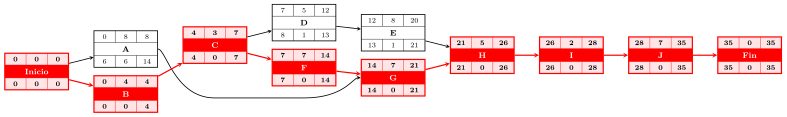

In [10]:
#| fig-cap: "Grafo Roy con las estimaciones agresivas y la cadena crítica"
#| label: fig-pert
proyecto.roy(durations=datos_proyecto['duration'], ranksep=1.2, nodesep=1.2)

Cálculo de los tiempos mínimos y máximos de los nodos del grafo Roy paso a paso (avance con los botones):

In [11]:
proyecto.display_roy_pasos(datos_proyecto['duration'])

In [12]:
#| tbl-cap: "Duración de cada ruta con las estimaciones agresivas"
#| label: tbl-rutas
detalle_rutas(R, datos_proyecto['agresiva'][R.columns])

,actividades,duración = suma,duración
Route_1,A - G - H - I - J,A(8) + G(7) + H(5) + I(2) + J(7) = 29,29.0
Route_2,B - C - D - E - H - I - J,B(4) + C(3) + D(5) + E(8) + H(5) + I(2) + J(7) = 34,34.0
Route_3,B - C - F - G - H - I - J,B(4) + C(3) + F(7) + G(7) + H(5) + I(2) + J(7) = 35,35.0


In [13]:
plan = proyecto.plan_cadena_critica(datos_proyecto, agresiva='agresiva', segura='segura')
cadena, T = plan.cadena, plan.duracion_cadena
margenes = plan.margen[cadena].astype(int)
Markdown(f'Cadena crítica: **{" - ".join(cadena)}**, {T} días, con {len(cadena)} actividades.')

Cadena crítica: **B - C - F - G - H - I - J**, 35 días, con 7 actividades.

In [14]:
#| tbl-cap: "Margen retirado de las actividades de la cadena"
#| label: tbl-margenes
tabla_margenes(datos_proyecto, cadena)

activity,B,C,F,G,H,I,J
segura,6,5,12,9,8,4,12
agresiva,4,3,7,7,5,2,7
margen = segura − agresiva,6 − 4 = 2,5 − 3 = 2,12 − 7 = 5,9 − 7 = 2,8 − 5 = 3,4 − 2 = 2,12 − 7 = 5


## Apartado 2

In [15]:
display(Markdown(pregunta_2))

2. Calcule el colchón del proyecto por el método de cortar y pegar y por el de la raíz de la suma de cuadrados.  

In [16]:
#| tbl-cap: "Colchón del proyecto por los dos métodos"
#| label: tbl-colchon
detalle_colchon(margenes, 'colchón del proyecto')

,colchón del proyecto
"cortar y pegar = 0,5·Σ márgenes","0,5·(2 + 2 + 5 + 2 + 3 + 2 + 5) = 0,5·21 = 10.5 → 11"
raíz = √(Σ márgenes²),√(2² + 2² + 5² + 2² + 3² + 2² + 5²) = √75 = 8.66 → 9


In [17]:
CP_cp = ceil(0.5 * margenes.sum() - 1e-9)
CP_rz = ceil(sqrt((margenes ** 2).sum()) - 1e-9)
Markdown(f'Cortar y pegar: **{CP_cp} días**; raíz de la suma de cuadrados: **{CP_rz} días**.')

Cortar y pegar: **11 días**; raíz de la suma de cuadrados: **9 días**.

## Apartado 3

In [18]:
display(Markdown(pregunta_3))

3. Suponga que la duración de cada actividad de la cadena es normal, independiente de las demás, con media su estimación agresiva y con la estimación segura como percentil 90, de modo que σ = margen/1,2816. ¿Con qué probabilidad termina la cadena en su duración más el colchón, con cada uno de los dos métodos?  

Con duraciones normales, la de la cadena es normal con media la suma de las medias (la duración agresiva de la cadena, $T$) y varianza la suma de las varianzas, $\sigma_C^2 = \sum_i (m_i/1{,}2816)^2$. La probabilidad de cumplir $T + CP$ es $\Phi(CP/\sigma_C)$.

In [19]:
sigma = margenes / 1.2816
sigma_cadena = float(np.sqrt((sigma ** 2).sum()))
display(pd.DataFrame({'σ = margen/1,2816': sigma.round(3), 'σ²': (sigma ** 2).round(3)}).T)
Markdown(f'σ de la cadena = √{(sigma ** 2).sum():.3f} = **{sigma_cadena:.3f} días** '
         f'(que es la raíz de la suma de cuadrados de los márgenes dividida por 1,2816: {sqrt((margenes ** 2).sum()):.3f}/1,2816).')

,B,C,F,G,H,I,J
"σ = margen/1,2816",1.561,1.561,3.901,1.561,2.341,1.561,3.901
σ²,2.435,2.435,15.221,2.435,5.479,2.435,15.221


σ de la cadena = √45.662 = **6.757 días** (que es la raíz de la suma de cuadrados de los márgenes dividida por 1,2816: 8.660/1,2816).

In [20]:
#| tbl-cap: "Probabilidad de terminar la cadena en T + CP"
#| label: tbl-probabilidad
pd.DataFrame({'colchón': [CP_cp, CP_rz], 'fecha T + CP': [T + CP_cp, T + CP_rz],
              'z = CP/σ': [f'{CP_cp}/{sigma_cadena:.3f} = {CP_cp / sigma_cadena:.3f}', f'{CP_rz}/{sigma_cadena:.3f} = {CP_rz / sigma_cadena:.3f}'],
              'P = Φ(z)': [round(norm.cdf(CP_cp / sigma_cadena), 4), round(norm.cdf(CP_rz / sigma_cadena), 4)]},
             index=['cortar y pegar', 'raíz']).T

,cortar y pegar,raíz
colchón,11,9
fecha T + CP,46,44
z = CP/σ,11/6.757 = 1.628,9/6.757 = 1.332
P = Φ(z),0.9482,0.9085


Sin redondear, el colchón de la raíz es exactamente $1{,}2816\,\sigma_C$: da la probabilidad 0,90 que se buscaba en cada actividad, ahora para la cadena completa (el redondeo al día superior la sube algo). El de cortar y pegar no tiene un nivel de confianza fijo: depende del número de actividades. El cálculo ignora las cadenas de alimentación, que se protegen con sus propios colchones.

## Apartado 4

In [21]:
display(Markdown(pregunta_4))

4. Si una cadena tuviera n actividades con el mismo margen m (tome el margen medio de esta cadena), ¿cómo crecen los dos colchones con n? ¿A partir de qué n es mayor el de cortar y pegar? ¿Qué método sobreprotege las cadenas largas y cuál protege mejor las cortas?  

In [22]:
#| tbl-cap: "Colchones y probabilidad de cumplir para n actividades de margen medio m"
#| label: tbl-n
m = float(margenes.mean())
n = np.arange(1, 13)
tabla_n = pd.DataFrame({'cortar y pegar = n·m/2': n * m / 2, 'raíz = √n·m': np.sqrt(n) * m,
                        'P con cortar y pegar = Φ(1,2816·√n/2)': norm.cdf(1.2816 * np.sqrt(n) / 2),
                        'P con raíz': norm.cdf(1.2816) + 0 * n}, index=pd.Index(n, name='n'))
tabla_n.round(3).T

n,1,2,3,4,5,6,7,8,9,10,11,12
cortar y pegar = n·m/2,1.500,3.000,4.500,6.0,7.500,9.000,10.500,12.000,13.500,15.000,16.500,18.000
raíz = √n·m,3.000,4.243,5.196,6.0,6.708,7.348,7.937,8.485,9.000,9.487,9.950,10.392
"P con cortar y pegar = Φ(1,2816·√n/2)",0.739,0.818,0.866,0.9,0.924,0.942,0.955,0.965,0.973,0.979,0.983,0.987
P con raíz,0.900,0.900,0.900,0.9,0.900,0.900,0.900,0.900,0.900,0.900,0.900,0.900


In [23]:
Markdown(f'Con m = {m:.2f} días, cortar y pegar crece linealmente (n·m/2) y la raíz como √n·m. Son iguales cuando '
         'n/2 = √n, es decir, n = 4: con más de cuatro actividades cortar y pegar da un colchón mayor, y su probabilidad '
         'de cumplir se acerca a 1 (sobreprotege las cadenas largas, a costa de alargar el compromiso); con menos de cuatro da un '
         f'colchón menor que la raíz y protege menos del 90 % (con n = 2, P = {norm.cdf(1.2816 * np.sqrt(2) / 2):.2f}). '
         f'Esta cadena tiene {len(cadena)} actividades: cortar y pegar le asigna {CP_cp - CP_rz} días más que la raíz.')

Con m = 3.00 días, cortar y pegar crece linealmente (n·m/2) y la raíz como √n·m. Son iguales cuando n/2 = √n, es decir, n = 4: con más de cuatro actividades cortar y pegar da un colchón mayor, y su probabilidad de cumplir se acerca a 1 (sobreprotege las cadenas largas, a costa de alargar el compromiso); con menos de cuatro da un colchón menor que la raíz y protege menos del 90 % (con n = 2, P = 0.82). Esta cadena tiene 7 actividades: cortar y pegar le asigna 2 días más que la raíz.